In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('student-mat.csv', sep=';')

In [4]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [5]:
df.shape

(395, 33)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [7]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='str')

In [8]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [9]:
categorical_columns = df.select_dtypes(include=['object']).columns
categorical_columns

C:\Users\benai\AppData\Local\Temp\ipykernel_18652\2864691023.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=['object']).columns


Index(['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob',
       'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities',
       'nursery', 'higher', 'internet', 'romantic'],
      dtype='str')

In [10]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns
numerical_columns

Index(['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel',
       'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2',
       'G3'],
      dtype='str')

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [13]:
df['school'].value_counts()

school
GP    349
MS     46
Name: count, dtype: int64

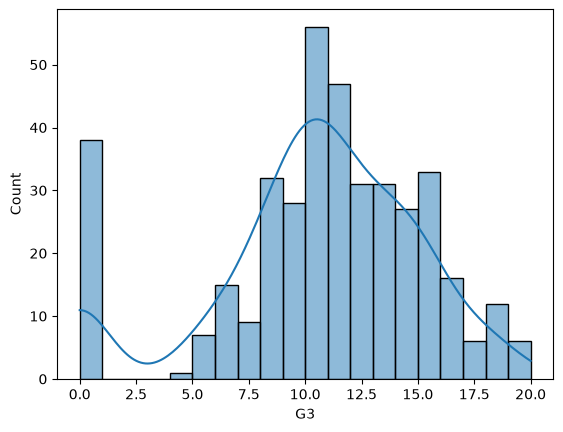

In [14]:
sns.histplot(data=df, x="G3", bins=20, kde=True)
plt.show()

In [15]:
print(df["G3"].describe())

print("Skewness:", df["G3"].skew())
print("Median:", df["G3"].median())
print("Mode:", df["G3"].mode().tolist())

count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64
Skewness: -0.7326723530443435
Median: 11.0
Mode: [10]


In [16]:
correlations = (
    df.corr(numeric_only=True)["G3"]
    .drop("G3")
    .sort_values(ascending=False)
)

print(correlations)

G2            0.904868
G1            0.801468
Medu          0.217147
Fedu          0.152457
studytime     0.097820
famrel        0.051363
absences      0.034247
freetime      0.011307
Walc         -0.051939
Dalc         -0.054660
health       -0.061335
traveltime   -0.117142
goout        -0.132791
age          -0.161579
failures     -0.360415
Name: G3, dtype: float64


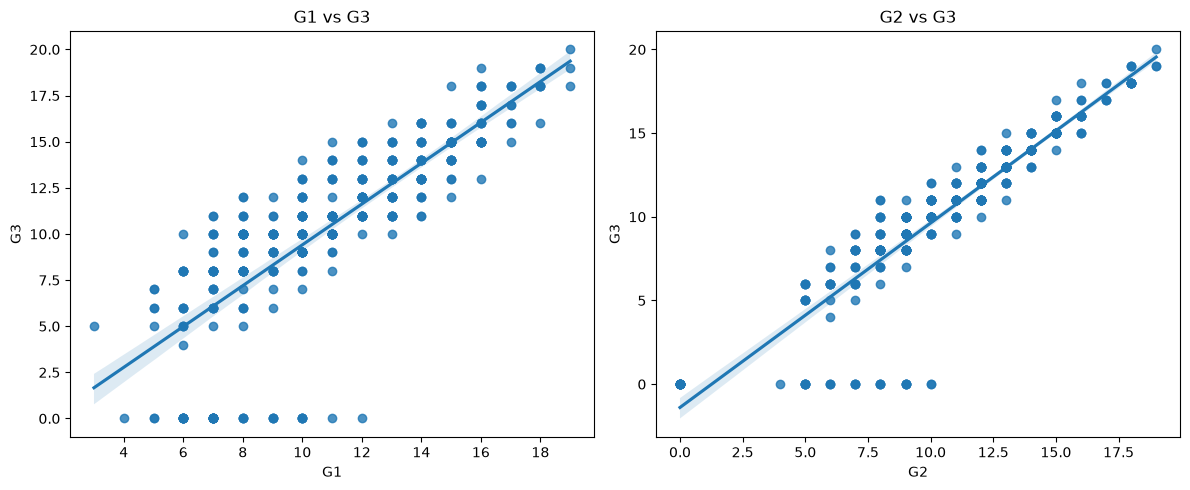

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.regplot(data=df, x="G1", y="G3", ax=axes[0])
axes[0].set_title("G1 vs G3")

sns.regplot(data=df, x="G2", y="G3", ax=axes[1])
axes[1].set_title("G2 vs G3")

plt.tight_layout()
plt.show()

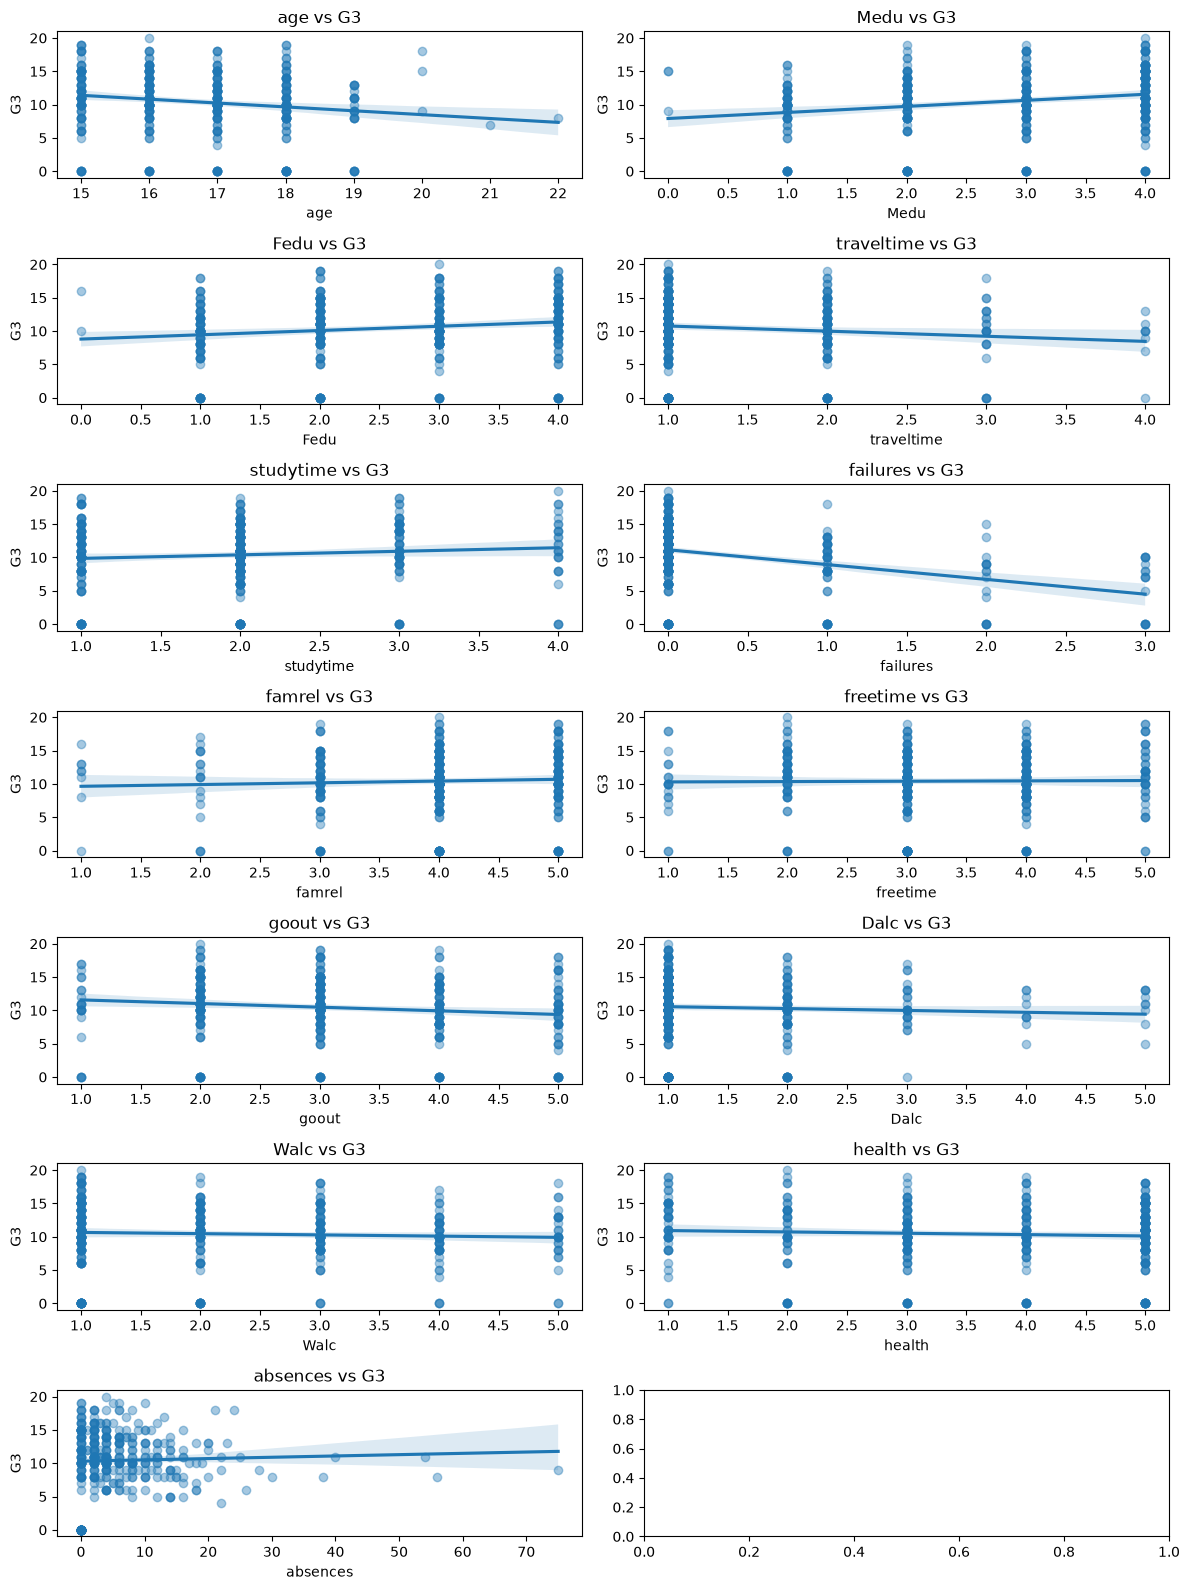

In [18]:
features = [
    'age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel',
    'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences'
]

fig, axes = plt.subplots(7, 2, figsize=(12, 16))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.regplot(
        data=df,
        x=col,
        y="G3",
        ax=axes[i],
        scatter_kws={"alpha": 0.4}
    )
    axes[i].set_title(f"{col} vs G3")

plt.tight_layout()
plt.show()

In [19]:
for col in categorical_columns:
    print(f"\n--- {col} ---")

    summary = (
        df.groupby(col, observed=True)["G3"]
        .agg(["count", "mean", "median"])
        .sort_values("mean", ascending=False)
    )

    print(summary.round(2))


--- school ---
        count   mean  median
school                      
GP        349  10.49    11.0
MS         46   9.85    10.0

--- sex ---
     count   mean  median
sex                      
M      187  10.91    11.0
F      208   9.97    10.0

--- address ---
         count   mean  median
address                      
U          307  10.67    11.0
R           88   9.51    10.0

--- famsize ---
         count   mean  median
famsize                      
LE3        114  11.00    11.0
GT3        281  10.18    11.0

--- Pstatus ---
         count   mean  median
Pstatus                      
A           41  11.20    11.0
T          354  10.32    11.0

--- Mjob ---
          count   mean  median
Mjob                          
health       34  12.15    13.0
teacher      58  11.05    11.0
services    103  11.02    11.0
other       141   9.82    11.0
at_home      59   9.15    10.0

--- Fjob ---
          count   mean  median
Fjob                          
teacher      29  11.97    14.0
he

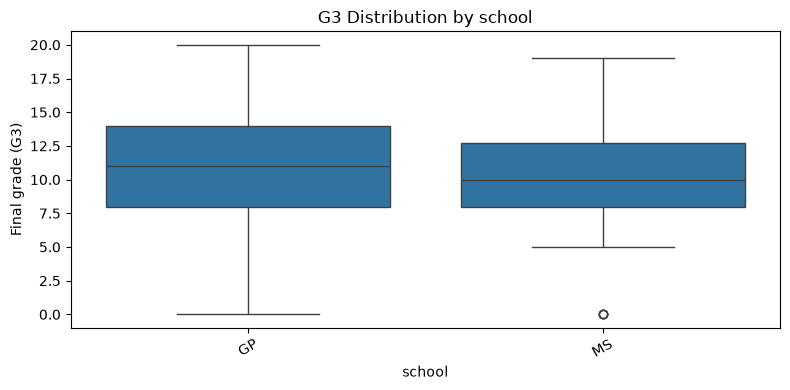

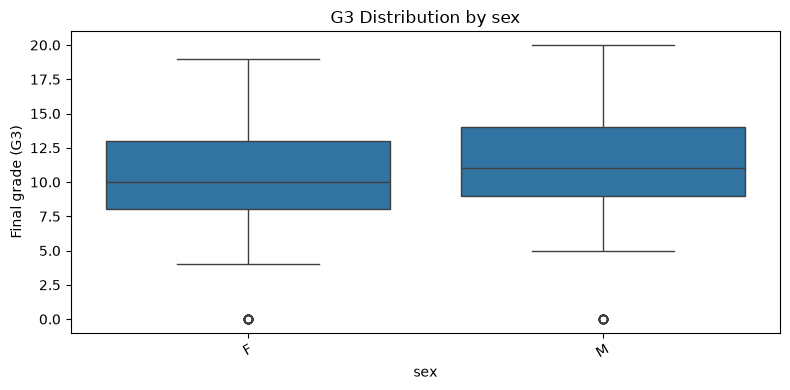

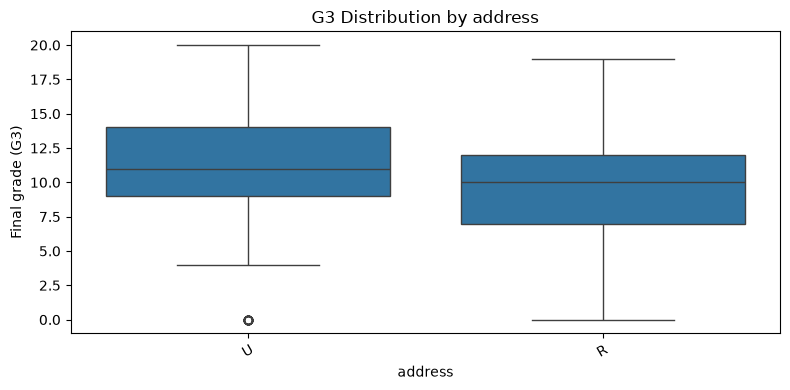

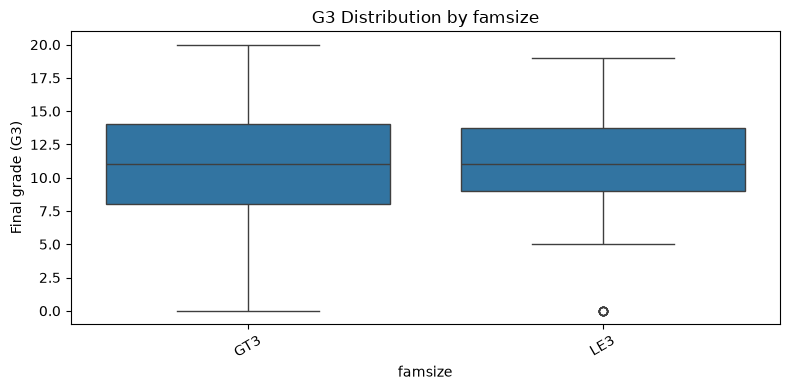

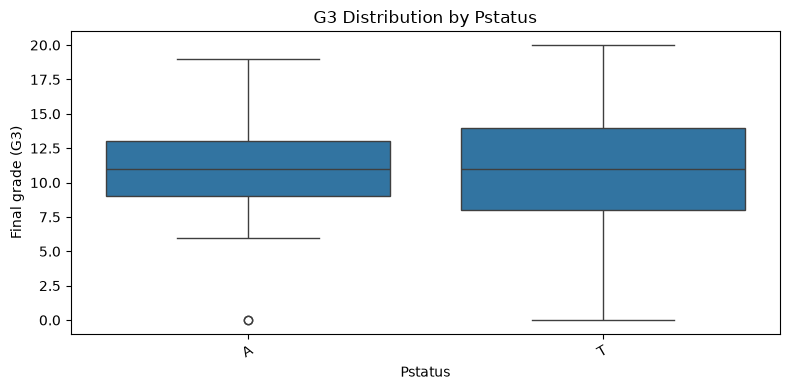

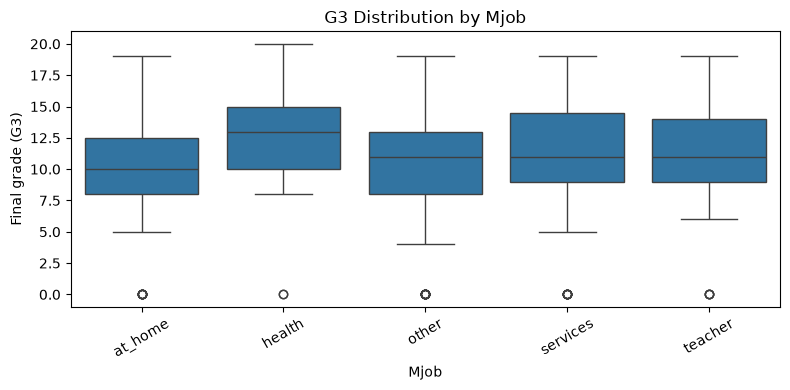

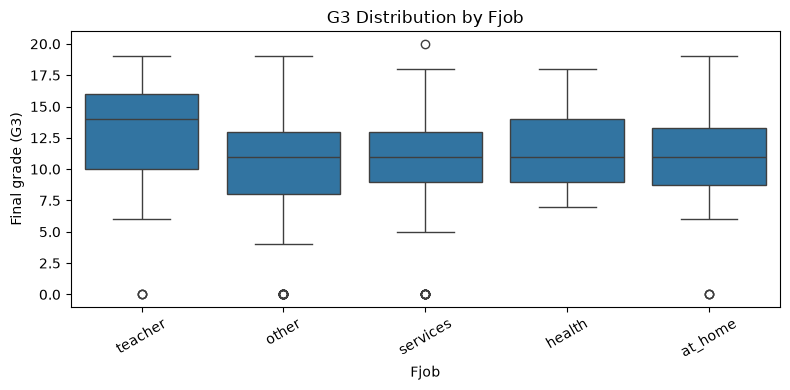

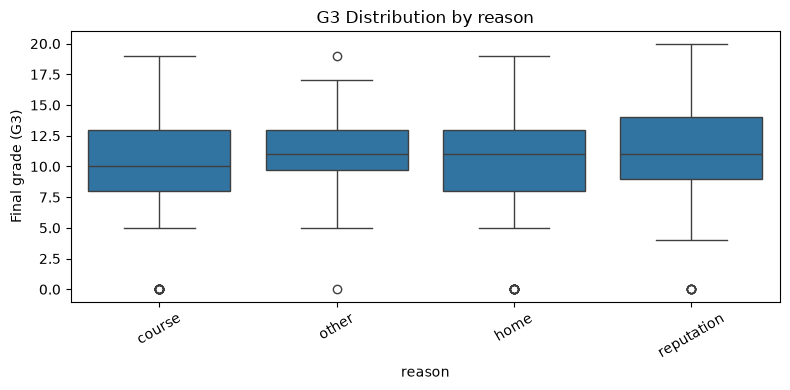

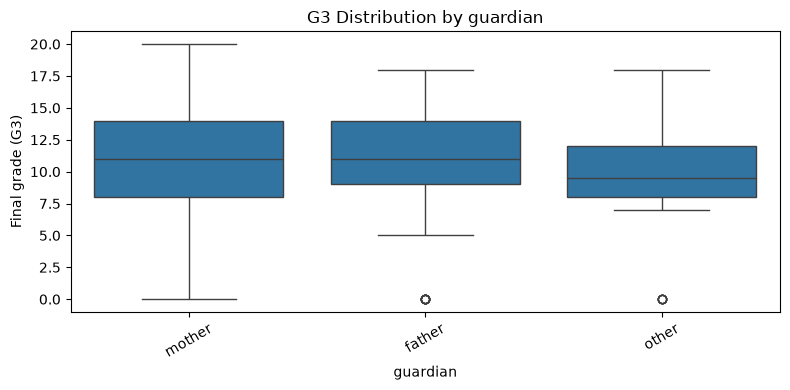

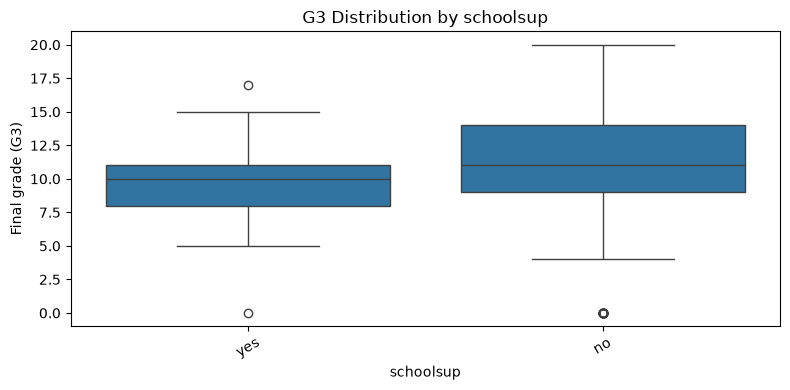

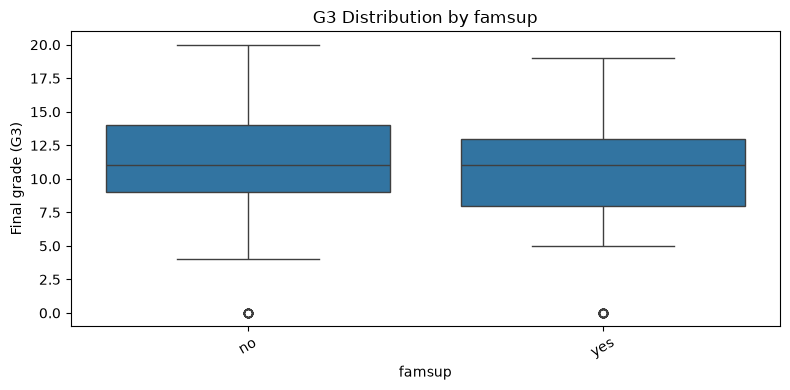

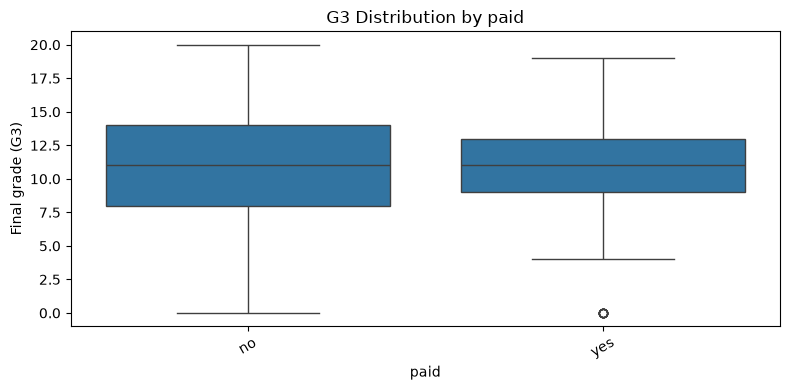

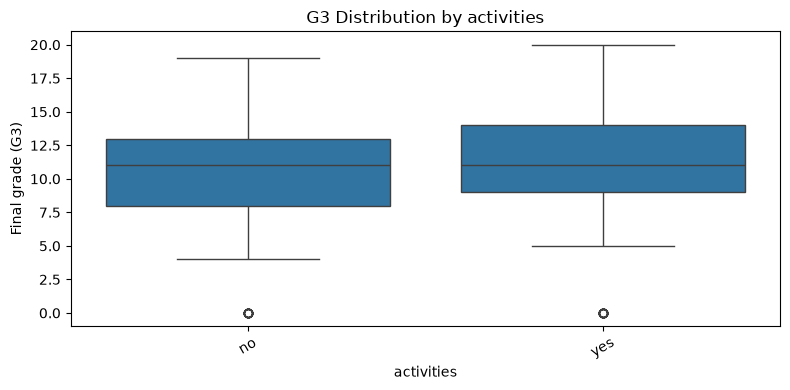

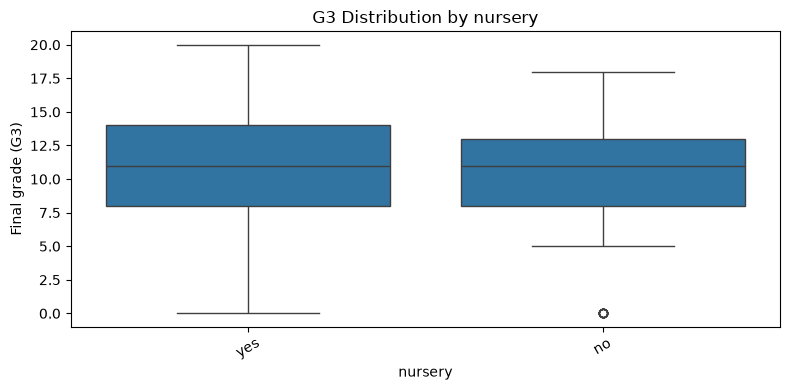

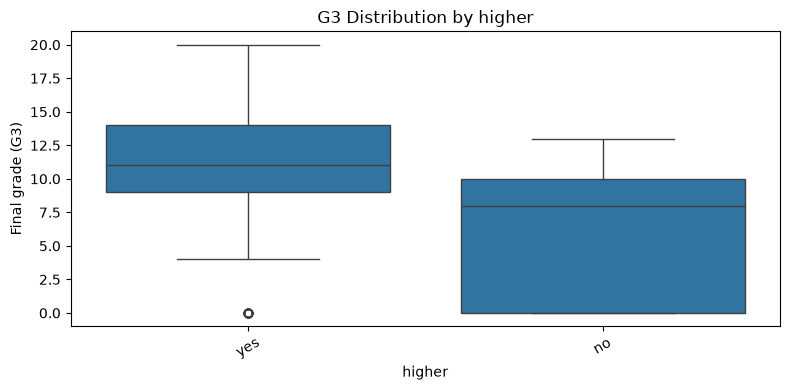

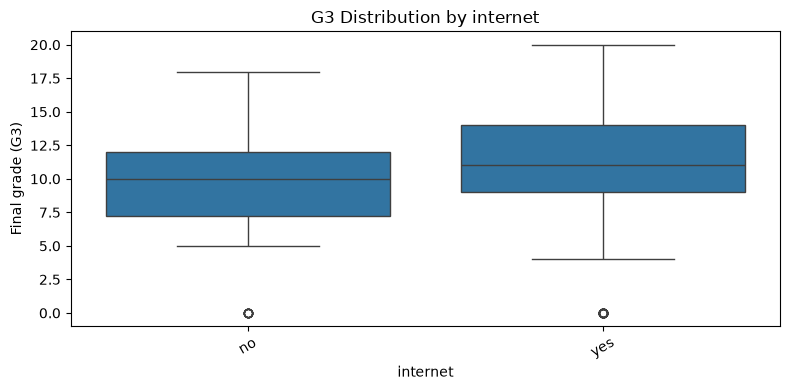

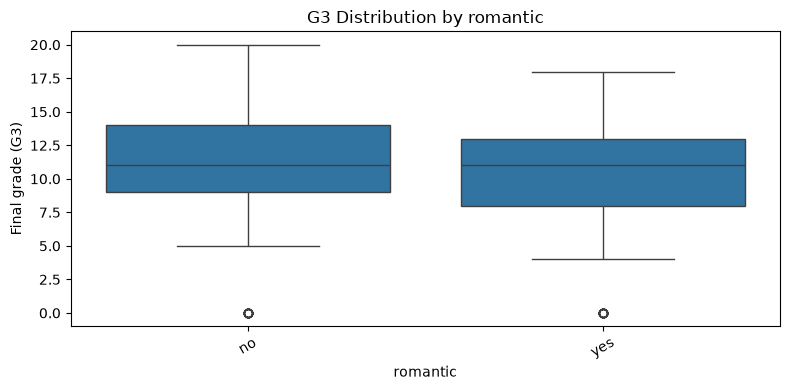

In [20]:
for col in categorical_columns:
    plt.figure(figsize=(8, 4))

    sns.boxplot(data=df, x=col, y="G3")

    plt.title(f"G3 Distribution by {col}")
    plt.xlabel(col)
    plt.ylabel("Final grade (G3)")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


sex
     count   mean  median   std
sex                            
F      208   9.97    10.0  4.62
M      187  10.91    11.0  4.50


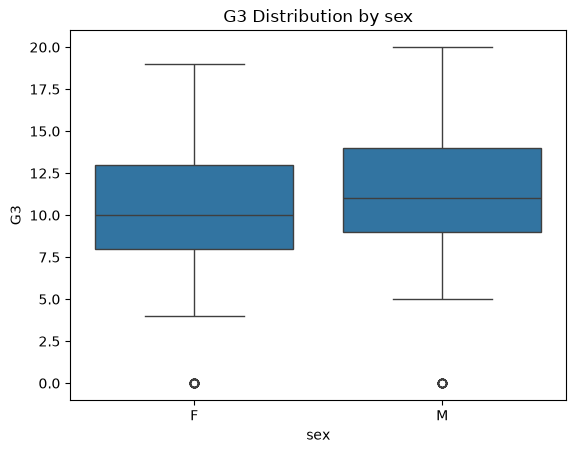


higher
        count   mean  median   std
higher                            
no         20   6.80     8.0  4.83
yes       375  10.61    11.0  4.49


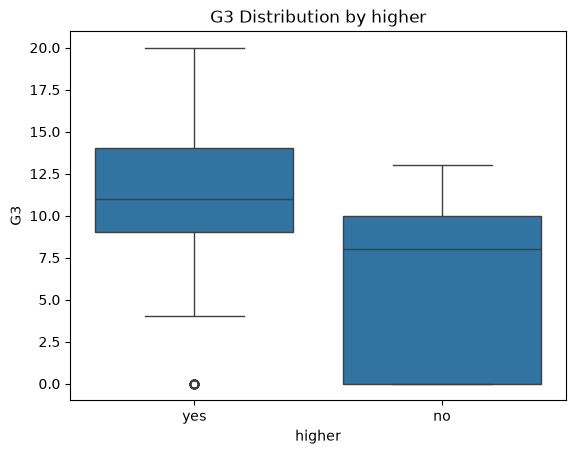

In [21]:
for col in ["sex", "higher"]:
    print(f"\n{col}")
    print(
        df.groupby(col, observed=True)["G3"]
        .agg(["count", "mean", "median", "std"])
        .round(2)
    )

    sns.boxplot(data=df, x=col, y="G3")
    plt.title(f"G3 Distribution by {col}")
    plt.show()

       G1     G2     G3
G1  1.000  0.852  0.801
G2  0.852  1.000  0.905
G3  0.801  0.905  1.000


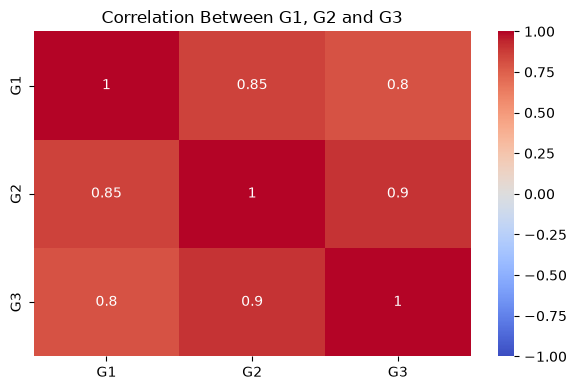

In [22]:
print(df[["G1", "G2", "G3"]].corr().round(3))

plt.figure(figsize=(6, 4))
sns.heatmap(
    df[["G1", "G2", "G3"]].corr(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Between G1, G2 and G3")
plt.tight_layout()
plt.show()

In [23]:
X = df.drop(columns=["G3"])
y = df["G3"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (395, 32)
y shape: (395,)


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (316, 32)
X_test: (79, 32)
y_train: (316,)
y_test: (79,)


In [25]:
print("Training target mean:", y_train.mean())
print("Testing target mean:", y_test.mean())

print("Training proportion:", len(X_train) / len(df))
print("Testing proportion:", len(X_test) / len(df))

Training target mean: 10.325949367088608
Testing target mean: 10.772151898734178
Training proportion: 0.8
Testing proportion: 0.2


In [26]:
# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Number of numerical features:", len(numerical_features))
print(numerical_features)

print("\nNumber of categorical features:", len(categorical_features))
print(categorical_features)

Number of numerical features: 15
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

Number of categorical features: 17
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


C:\Users\benai\AppData\Local\Temp\ipykernel_18652\2026000691.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [28]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Build the complete pipeline
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

# Train using all features
baseline_model.fit(X_train, y_train)

# Predict on the untouched test set
y_pred = baseline_model.predict(X_test)

# Evaluate
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")

MAE:  1.188
RMSE: 2.007
R²:   0.804


In [29]:
import pandas as pd
from sklearn.inspection import permutation_importance

importance_result = permutation_importance(
    baseline_model,
    X_train,
    y_train,
    scoring="neg_mean_absolute_error",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance_mean": importance_result.importances_mean,
    "importance_std": importance_result.importances_std
}).sort_values("importance_mean", ascending=False)

print(importance_df.to_string(index=False))

   feature  importance_mean  importance_std
        G2         3.957896        0.155124
  absences         0.736645        0.076109
    reason         0.138483        0.018336
        G1         0.091797        0.010049
       age         0.077301        0.008446
      Fjob         0.058828        0.005975
      Walc         0.047660        0.005392
    famrel         0.045790        0.005696
    health         0.038832        0.004846
      Mjob         0.037614        0.004257
  guardian         0.037021        0.005487
     goout         0.029786        0.002855
      Fedu         0.021127        0.002190
  romantic         0.020762        0.003432
 studytime         0.019804        0.002341
 schoolsup         0.019775        0.004113
  freetime         0.019774        0.002498
activities         0.017751        0.003461
   famsize         0.015793        0.002350
  failures         0.013963        0.001457
      Medu         0.013555        0.002195
      Dalc         0.011714     

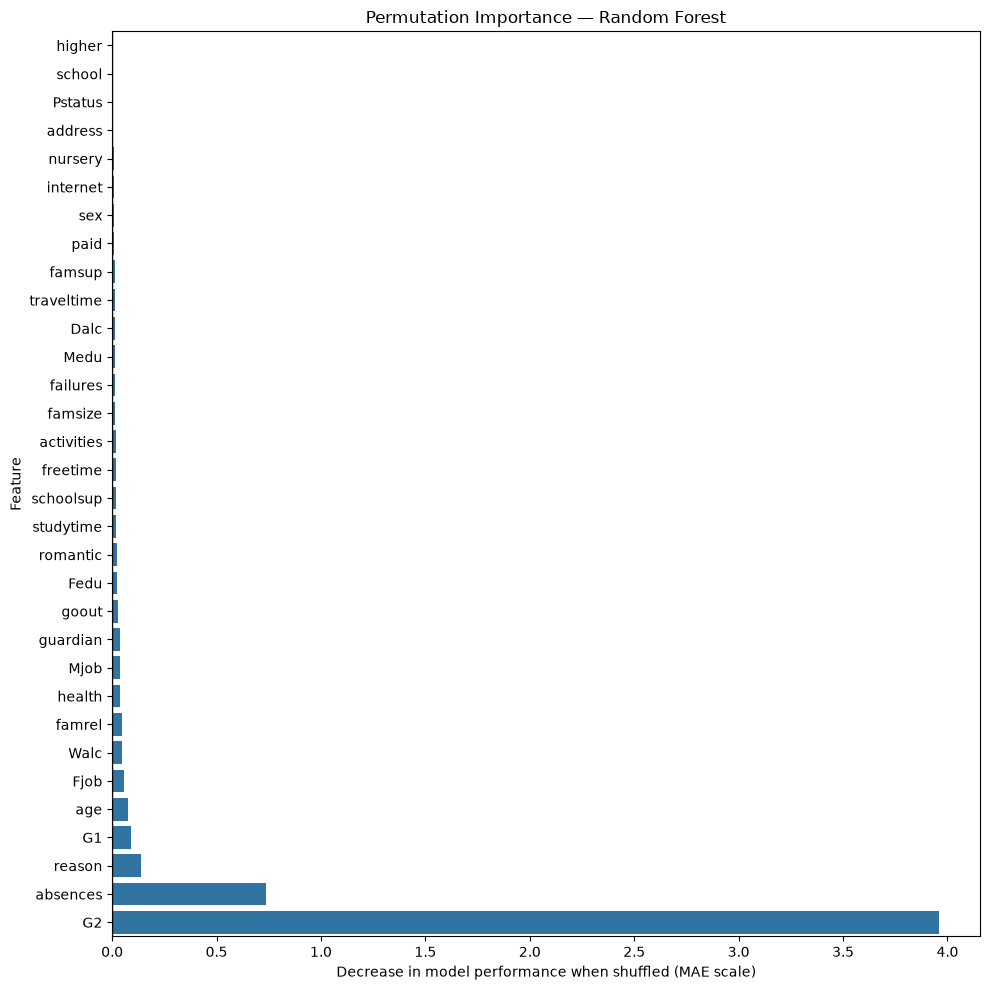

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

top_features = importance_df.sort_values(
    "importance_mean",
    ascending=True
)

plt.figure(figsize=(10, 10))

sns.barplot(
    data=top_features,
    x="importance_mean",
    y="feature"
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Permutation Importance — Random Forest")
plt.xlabel("Decrease in model performance when shuffled (MAE scale)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [31]:
selected_features = [
    "G2", "absences", "reason", "G1", "age",
    "Fjob", "Walc", "famrel", "health", "Mjob", "guardian"
]

X_train_selected = X_train[selected_features]
X_test_selected = X_test[selected_features]

print("Original number of features:", X_train.shape[1])
print("Selected number of features:", X_train_selected.shape[1])

Original number of features: 32
Selected number of features: 11


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor

# Identify numerical and categorical features in the subset
numerical_selected = X_train_selected.select_dtypes(
    include="number"
).columns.tolist()

categorical_selected = X_train_selected.select_dtypes(
    exclude="number"
).columns.tolist()

# Preprocessing
numerical_transformer_selected = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer_selected = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_selected = ColumnTransformer([
    ("num", numerical_transformer_selected, numerical_selected),
    ("cat", categorical_transformer_selected, categorical_selected)
])

# Build the simpler model
simple_model = Pipeline([
    ("preprocessor", preprocessor_selected),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

# Train
simple_model.fit(X_train_selected, y_train)

# Predict
y_pred_simple = simple_model.predict(X_test_selected)

In [33]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae_simple = mean_absolute_error(y_test, y_pred_simple)
rmse_simple = np.sqrt(mean_squared_error(y_test, y_pred_simple))
r2_simple = r2_score(y_test, y_pred_simple)

print("Simple Model Results")
print("MAE:", round(mae_simple, 3))
print("RMSE:", round(rmse_simple, 3))
print("R2:", round(r2_simple, 3))

Simple Model Results
MAE: 1.201
RMSE: 2.054
R2: 0.794


In [34]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Select the 5 features
selected_features_5 = [
    "G2",
    "absences",
    "reason",
    "G1",
    "age"
]

X_train_5 = X_train[selected_features_5]
X_test_5 = X_test[selected_features_5]

# 2. Separate numerical and categorical features
numerical_features_5 = X_train_5.select_dtypes(
    include="number"
).columns.tolist()

categorical_features_5 = X_train_5.select_dtypes(
    exclude="number"
).columns.tolist()

# 3. Preprocessing for numerical features
numerical_transformer_5 = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# 4. Preprocessing for categorical features
categorical_transformer_5 = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# 5. Combine the preprocessing steps
preprocessor_5 = ColumnTransformer([
    ("num", numerical_transformer_5, numerical_features_5),
    ("cat", categorical_transformer_5, categorical_features_5)
])

# 6. Build the model
model_5 = Pipeline([
    ("preprocessor", preprocessor_5),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

# 7. Train the model
model_5.fit(X_train_5, y_train)

# 8. Make predictions
y_pred_5 = model_5.predict(X_test_5)

# 9. Evaluate the model
mae_5 = mean_absolute_error(y_test, y_pred_5)
rmse_5 = np.sqrt(mean_squared_error(y_test, y_pred_5))
r2_5 = r2_score(y_test, y_pred_5)

print("Random Forest — 5 Features")
print("Number of features:", len(selected_features_5))
print("MAE:", round(mae_5, 3))
print("RMSE:", round(rmse_5, 3))
print("R2:", round(r2_5, 3))


Random Forest — 5 Features
Number of features: 5
MAE: 1.233
RMSE: 2.191
R2: 0.766
